In [1]:
import pandas as pd
import numpy as np

In [2]:
import pandas as pd
import numpy as np
train_data = pd.read_csv("train_data.txt", header=None)
val_data = pd.read_csv("valid_data.txt", header=None)
test_data = pd.read_csv("test_data.txt", header=None)
train_data.columns = ["items"]
val_data.columns = ["items"]
test_data.columns = ["items"]

data = pd.concat([train_data,val_data,test_data])
def str_to_int_list(s):
        return [int(num)-1 for num in s.split()]

    # 使用 apply() 函数应用到 DataFrame 的列上
data['items'] = data['items'].apply(str_to_int_list)
items = data["items"].values.tolist()
items_pop = np.zeros(12101)
for seq in  items:
    for item in seq:
        items_pop[item] +=1
np.save("./items_pop.npy", items_pop)

In [10]:
df = [{'seq_size':10, 'item_num':12101}]
df = pd.DataFrame(df)
df.to_pickle("./data_statis.df")

In [2]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# 设置图形风格
sns.set(style="ticks")
import matplotlib.font_manager as fm
fm.fontManager.addfont('../../fonts/times.ttf')
fm.fontManager.addfont('../../fonts/timesbd.ttf')
fm.fontManager.addfont('../../fonts/timesbi.ttf')
fm.fontManager.addfont('../../fonts/timesi.ttf')
plt.rc('font',family='Times New Roman', weight='bold')

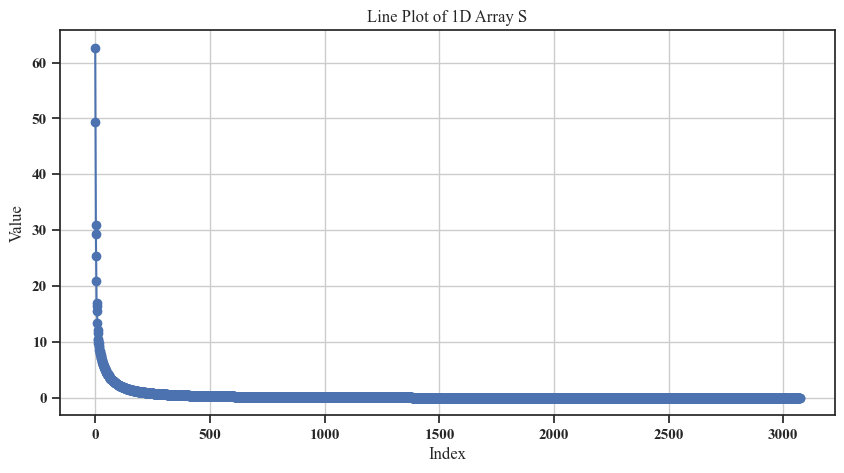

In [4]:
wordvec_df = pd.read_pickle("./3large_emb.pickle")
word_vectors = np.stack(wordvec_df)
all_samples = word_vectors * 40
mean = np.mean(all_samples, axis=0)
cov = np.cov( all_samples - mean, rowvar=False)
U, S, VT = np.linalg.svd(cov, full_matrices=False)
plt.figure(figsize=(10, 5))
plt.plot(S, marker='o', linestyle='-', color='b')  # 用折线图展示数组
plt.title("Line Plot of 1D Array S")
plt.xlabel("Index")
plt.ylabel("Value")
plt.grid(True)
plt.show()

In [5]:
wordvec_df.shape

(12101, 3072)

In [7]:
import pandas as pd
import numpy as np

def trans_data(input_path, output_path, target_length, pad_value):
    train_data = pd.read_csv(input_path, header=None)
    train_data.columns = ["items"]

    def str_to_int_list(s):
        return [int(num)-1 for num in s.split()]

    # 使用 apply() 函数应用到 DataFrame 的列上
    train_data['items'] = train_data['items'].apply(str_to_int_list)
    train_data['len_seq'] = train_data['items'].apply(lambda x:len(x))

    new_rows = []  # 用于存放新的行
    for _, row in train_data.iterrows():
        seqs = row['items']
        len_seqs = row['len_seq']
    
        if len_seqs == 1:
            continue
        elif len_seqs <= 11:
            # len_seqs 小于等于 6 时，将最后一个元素作为 target，其余部分作为 seqs
            new_seqs = seqs[:-1]  # 除去最后一个元素
            target = seqs[-1]     # 最后一个元素作为 target
            new_rows.append({'seq': new_seqs, 'len_seq':len_seqs-1, 'next': target})
        else:
            # len_seqs 大于 6 时，以 5 为窗口生成子序列
            for i in range(len_seqs - 10):
                new_seqs = seqs[i:i+5]  # 窗口长度为 5
                target = seqs[i+5]      # 窗口之后的第一个元素作为 target
                new_rows.append({'seq': new_seqs, 'len_seq':10, 'next': target})
    expanded_df = pd.DataFrame(new_rows)

    def pad_to_length(seqs, target_length, pad_value=0):
        """将列表 seqs 的长度补充到 target_length，前置填充 pad_value"""
        if len(seqs) < target_length:
            return [pad_value] * (target_length - len(seqs)) + seqs
        return seqs

    # 对 len_seqs 小于 target_length 的行进行补充
    expanded_df['seq'] = expanded_df['seq'].apply(
        lambda x: pad_to_length(x, target_length=target_length, pad_value=pad_value) if len(x) < 10 else x
    )

    expanded_df.to_pickle(output_path)


In [8]:
import pandas as pd
import numpy as np

In [9]:
trans_data("./train_data.txt","./train_data.df", 10, 12101)
trans_data("./test_data.txt","./test_data.df", 10, 12101)
trans_data("./valid_data.txt","./val_data.df", 10, 12101)

In [10]:
df = pd.read_pickle("./train_data.df")

## SID

In [26]:
import pickle, numpy as np, faiss, os

# 读取你的向量 (N, d)
wordvec_df   = pickle.load(open('3large_emb.pickle', 'rb'))
word_vectors = np.stack(wordvec_df).astype('float32')
all_samples = word_vectors * 40
mean = np.mean(all_samples, axis=0)
cov = np.cov( all_samples - mean, rowvar=False)
U, S, VT = np.linalg.svd(cov, full_matrices=False)
W = U.dot(np.diag(np.sqrt(1/S)))
word_vectors = np.dot((all_samples - mean), W)[:,:2048]
N, d = word_vectors.shape
print(f"{N=}, {d=}")

N=12101, d=2048


In [27]:
m, nbits = 16, 2
# m, nbits = 16, 2
use_opq  = False
train_sz = min(100_000, N)
train_vecs = word_vectors[:train_sz]

# 2.1 可选 OPQ 旋转（提升量化精度）
if use_opq:
    opq = faiss.OPQMatrix(d, m)        # 把 d 维旋转后再做 PQ
    opq.train(train_vecs)
    train_vecs_rot = opq.apply_py(train_vecs)
else:
    opq = None
    train_vecs_rot = train_vecs

# 2.2 训练 ProductQuantizer (仅 PQ，不建索引)
pq = faiss.ProductQuantizer(d, m, nbits)   # d must be divisible by m
pq.train(train_vecs_rot)
print("PQ 训练完毕")

# 3.1 如有 OPQ，先对全量向量做同样旋转
vecs_rot = opq.apply_py(word_vectors) if use_opq else word_vectors

# 3.2 编码：返回 (N, m) uint8
codes = pq.compute_codes(vecs_rot)
print(codes.shape, codes.dtype)   # (N, m) uint8

PQ 训练完毕
(12101, 4) uint8


In [28]:
import numpy as np

# 假设 codes 是 (N, m) 的 uint8 数组
# 先转为 bytes，每行变成一个唯一字符串
flattened = codes.view([('', codes.dtype)] * codes.shape[1]).squeeze()

# 找到唯一的编码及其计数
unique_codes, counts = np.unique(flattened, return_counts=True)

# 是否存在重复
has_duplicates = np.any(counts > 1)

print(f"是否存在重复 Semantic ID？ {has_duplicates}")
print(f"共有 {np.sum(counts > 1)} 个重复的编码；重复次数最多为 {np.max(counts)}")

from collections import defaultdict

# 构建 hash -> index 列表
hash_dict = defaultdict(list)
for idx, row in enumerate(flattened):
    hash_dict[row.tobytes()].append(idx)

# 筛出有冲突的
duplicate_groups = [idxs for idxs in hash_dict.values() if len(idxs) > 1]

# 输出部分重复 ID 的索引组
for group in duplicate_groups:
    print("重复项索引组:", group)

是否存在重复 Semantic ID？ True
共有 28 个重复的编码；重复次数最多为 2
重复项索引组: [118, 3759]
重复项索引组: [439, 3746]
重复项索引组: [795, 1098]
重复项索引组: [839, 4769]
重复项索引组: [2497, 2814]
重复项索引组: [2502, 4671]
重复项索引组: [2890, 7964]
重复项索引组: [2893, 9761]
重复项索引组: [3584, 3585]
重复项索引组: [4545, 8079]
重复项索引组: [4600, 4601]
重复项索引组: [5314, 5984]
重复项索引组: [6689, 6708]
重复项索引组: [6860, 6862]
重复项索引组: [7843, 7845]
重复项索引组: [8115, 9660]
重复项索引组: [8386, 8387]
重复项索引组: [8942, 9344]
重复项索引组: [9677, 9679]
重复项索引组: [9744, 11154]
重复项索引组: [10217, 10220]
重复项索引组: [10459, 10466]
重复项索引组: [11230, 11232]
重复项索引组: [11436, 11437]
重复项索引组: [11550, 11791]
重复项索引组: [11750, 11751]
重复项索引组: [11851, 11859]
重复项索引组: [12081, 12083]


In [29]:
import numpy as np
from collections import defaultdict

def append_disambiguating_token(codes):
    N, m = codes.shape

    # 把每行编码为 bytes，用于查重
    flattened = codes.view([('', codes.dtype)] * m).squeeze()

    # 构建哈希 -> 索引组
    hash_to_indices = defaultdict(list)
    for idx, row in enumerate(flattened):
        hash_to_indices[row.tobytes()].append(idx)

    # 初始化新列为 0（默认：非重复）
    disambiguate_token = np.zeros((N, 1), dtype=np.uint8)

    # 对重复项分配唯一编号
    for indices in hash_to_indices.values():
        if len(indices) > 1:
            for i, idx in enumerate(indices):
                disambiguate_token[idx, 0] = i + 1   # 注意从 1 开始，0 保留给非冲突项

    # 拼接成新 codes (N, m+1)
    codes_new = np.hstack([codes, disambiguate_token])
    return codes_new

codes_new = append_disambiguating_token(codes)
print(codes_new.shape)     # (N, m+1)
print("是否仍有重复？", np.unique(codes_new.view([('', np.uint8)] * codes_new.shape[1])).size < codes_new.shape[0])

(12101, 5)
是否仍有重复？ False


In [30]:
import pickle

# 保存为 .pkl 文件
with open("3small_256_4_1.pickle", "wb") as f:
    pickle.dump(codes_new, f)